In [2]:
import pandas as pd

H1 = pd.read_csv("H1.csv")
H2 = pd.read_csv("H2.csv")

print(H1.shape)
print(H2.shape)

(40060, 31)
(79330, 31)


In [3]:
H1['hotel'] = 0
H2['hotel'] = 1

df = pd.concat([H1, H2], ignore_index=True)

print(df.shape)

(119390, 32)


In [4]:
df['Children'] = df['Children'].fillna(0)
df['Country'] = df['Country'].fillna('Unknown')
df['Agent'] = df['Agent'].fillna(0)
df['Company'] = df['Company'].fillna(0)

In [5]:
df = df[~((df['Adults'] == 0) & 
          (df['Children'] == 0) & 
          (df['Babies'] == 0))]

In [6]:
df = df[~(
    (df['StaysInWeekendNights'] == 0) &
    (df['StaysInWeekNights'] == 0)
)]

print(df.shape)

(118565, 32)


In [7]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
IsCanceled,118565.0,0.372589,0.483496,0.00,0.0,0.0,1.0,1.0
LeadTime,118565.0,104.505832,106.915519,0.00,18.0,70.0,161.0,709.0
ArrivalDateYear,118565.0,2016.157635,0.707714,2015.00,2016.0,2016.0,2017.0,2017.0
ArrivalDateWeekNumber,118565.0,27.157028,13.589350,1.00,16.0,28.0,38.0,53.0
ArrivalDateDayOfMonth,118565.0,15.799595,8.782227,1.00,8.0,16.0,23.0,31.0
StaysInWeekendNights,118565.0,0.932096,0.995462,0.00,0.0,1.0,2.0,19.0
StaysInWeekNights,118565.0,2.512790,1.893258,0.00,1.0,2.0,3.0,50.0
Adults,118565.0,1.860009,0.575441,0.00,2.0,2.0,2.0,55.0
Children,118565.0,0.104196,0.399119,0.00,0.0,0.0,0.0,10.0
Babies,118565.0,0.007962,0.097560,0.00,0.0,0.0,0.0,10.0


In [8]:
df = df[df['ADR'] >= 0].copy()

print(df.shape)

(118564, 32)


In [9]:
before = len(df)

df = df.drop_duplicates().copy()

after = len(df)

print("Rows removed:", before - after)
print("New shape:", df.shape)

Rows removed: 31926
New shape: (86638, 32)


In [10]:
print(df['IsCanceled'].value_counts())
print()
print(df['IsCanceled'].value_counts(normalize=True) * 100)

0    62652
1    23986
Name: IsCanceled, dtype: int64

0    72.314689
1    27.685311
Name: IsCanceled, dtype: float64


In [11]:
numerical_cols = df.select_dtypes(include=['int64', 'float64']).columns

print(df[numerical_cols].describe().T.to_string())

                               count         mean        std     min     25%     50%        75%     max
IsCanceled                   86638.0     0.276853   0.447446     0.0     0.0     0.0     1.0000     1.0
LeadTime                     86638.0    80.291766  86.073301     0.0    12.0    50.0   126.0000   709.0
ArrivalDateYear              86638.0  2016.212228   0.685981  2015.0  2016.0  2016.0  2017.0000  2017.0
ArrivalDateWeekNumber        86638.0    26.822422  13.652372     1.0    16.0    27.0    37.0000    53.0
ArrivalDateDayOfMonth        86638.0    15.817805   8.835849     1.0     8.0    16.0    23.0000    31.0
StaysInWeekendNights         86638.0     1.011427   1.027495     0.0     0.0     1.0     2.0000    19.0
StaysInWeekNights            86638.0     2.641785   2.035172     0.0     1.0     2.0     4.0000    50.0
Adults                       86638.0     1.880503   0.622273     0.0     2.0     2.0     2.0000    55.0
Children                     86638.0     0.139304   0.456895    

In [12]:
print("Adults > 4:")
print(df[df['Adults'] > 4][['Adults', 'Children', 'Babies', 'ADR', 'StaysInWeekendNights', 'StaysInWeekNights']].to_string(index=False))

print("\nADR > 1000:")
print(df[df['ADR'] > 1000][['Adults', 'Children', 'Babies', 'ADR', 'StaysInWeekendNights', 'StaysInWeekNights']].to_string(index=False))

print("\nParking spaces > 2:")
print(df[df['RequiredCarParkingSpaces'] > 2][['Adults', 'Children', 'Babies', 'RequiredCarParkingSpaces']].to_string(index=False))

Adults > 4:
 Adults  Children  Babies  ADR  StaysInWeekendNights  StaysInWeekNights
     40       0.0       0  0.0                     0                  3
     26       0.0       0  0.0                     2                  5
     50       0.0       0  0.0                     1                  2
     26       0.0       0  0.0                     2                  5
     26       0.0       0  0.0                     2                  5
     27       0.0       0  0.0                     1                  3
     27       0.0       0  0.0                     1                  3
     26       0.0       0  0.0                     2                  5
     26       0.0       0  0.0                     2                  5
     55       0.0       0  0.0                     2                  0
     20       0.0       0  0.0                     2                  5
      6       0.0       0  0.0                     2                  5
      5       0.0       0  0.0                     2

In [13]:
print(df['Adults'].value_counts().sort_index().to_string())

0       219
1     16317
2     64107
3      5919
4        60
5         2
6         1
10        1
20        2
26        5
27        2
40        1
50        1
55        1


In [14]:
print(df[df['Adults'] == 0][
    ['Adults', 'Children', 'Babies', 'ADR',
     'StaysInWeekendNights', 'StaysInWeekNights', 'IsCanceled']
].to_string(index=False))

 Adults  Children  Babies    ADR  StaysInWeekendNights  StaysInWeekNights  IsCanceled
      0       3.0       0   9.00                     1                  1           0
      0       2.0       0   6.00                     0                  3           0
      0       2.0       0   6.00                     2                  0           0
      0       2.0       0   0.00                     0                  1           0
      0       2.0       0   6.00                     1                  3           1
      0       3.0       0 104.25                     1                  0           1
      0       2.0       1  77.00                     0                  1           0
      0       2.0       0   6.00                     0                  3           0
      0       2.0       0  77.25                     0                  2           1
      0       2.0       0  83.58                     2                  1           0
      0       2.0       0  15.00                     1

In [15]:
df = df[df['Adults'] < 11].copy()

print(df.shape)

(86626, 32)


In [16]:
df = df[df['ADR'] < 1000].copy()

print(df.shape)

(86625, 32)


In [17]:
df = df[df['StaysInWeekNights'] < 50].copy()

print(df.shape)

(86624, 32)


In [18]:
# Calculate length of stay and estimated booking value
df["TotalNights"] = (
    df["StaysInWeekendNights"] + df["StaysInWeekNights"]
)
df["BookingValue"] = df["ADR"] * df["TotalNights"]

# Compare the value of canceled and non-canceled bookings
summary = df.groupby("IsCanceled").agg(
    Bookings=("BookingValue", "size"),
    AverageBookingValue=("BookingValue", "mean"),
    TotalBookingValue=("BookingValue", "sum")
).rename(index={0: "Not canceled", 1: "Canceled"})

display(summary.round(2))

,Bookings,AverageBookingValue,TotalBookingValue
IsCanceled,,,
Not canceled,62651,366.47,22960021.95
Canceled,23973,478.82,11478642.98


In [19]:
hotel_summary = df.groupby("hotel").agg(
    TotalBookings=("IsCanceled", "size"),
    CanceledBookings=("IsCanceled", "sum"),
    AverageBookingValue=("BookingValue", "mean"),
    TotalBookingValue=("BookingValue", "sum")
)

hotel_summary["CancellationRate"] = (
    hotel_summary["CanceledBookings"]
    / hotel_summary["TotalBookings"] * 100
)

hotel_summary["CanceledBookingValue"] = (
    df[df["IsCanceled"] == 1]
    .groupby("hotel")["BookingValue"].sum()
)

display(hotel_summary.round(2))

,TotalBookings,CanceledBookings,AverageBookingValue,TotalBookingValue,CancellationRate,CanceledBookingValue
hotel,,,,,,
0,33582,7952,466.89,15679031.57,23.68,4869587.35
1,53042,16021,353.68,18759633.36,30.20,6609055.63


,Bookings,CancellationRate,TotalBookingValue,CanceledBookingValue,CanceledValueSharePct
MarketSegment,,,,,
Online TA,51285,35.55,22259326.55,9292901.94,41.75
Direct,11644,14.82,4847452.75,929714.23,19.18
Offline TA/TO,13743,14.92,5411064.95,815608.82,15.07
Groups,4891,27.21,1238520.72,315619.75,25.48
Corporate,4155,12.20,594144.08,110415.25,18.58
Aviation,222,19.82,83033.36,14065.00,16.94
Complementary,682,12.17,5074.52,269.99,5.32
Undefined,2,100.00,48.00,48.00,100.00


<Axes: title={'center': 'Canceled booking value by market segment'}, xlabel='Market segment', ylabel='Booking value (dataset currency units)'>

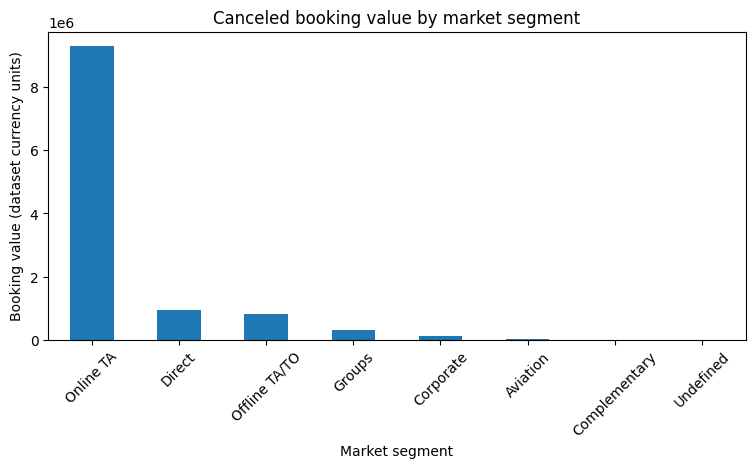

In [20]:
# Summarize cancellation frequency and booking value by market segment
segment_df = df.assign(
    CanceledValue=df["BookingValue"] * df["IsCanceled"]
)

segment_summary = segment_df.groupby("MarketSegment").agg(
    Bookings=("IsCanceled", "size"),
    CancellationRate=("IsCanceled", "mean"),
    TotalBookingValue=("BookingValue", "sum"),
    CanceledBookingValue=("CanceledValue", "sum")
)

segment_summary["CancellationRate"] *= 100

segment_summary["CanceledValueSharePct"] = (
    segment_summary["CanceledBookingValue"]
    / segment_summary["TotalBookingValue"].replace(0, float("nan"))
    * 100
)

segment_summary = segment_summary.sort_values(
    "CanceledBookingValue", ascending=False
)

display(segment_summary.round(2))

segment_summary["CanceledBookingValue"].plot.bar(
    figsize=(9, 4),
    title="Canceled booking value by market segment",
    ylabel="Booking value (dataset currency units)",
    xlabel="Market segment",
    rot=45
)